# Glacial Lake Segmentation — Attn-ResUNet34 Final Reproducible Run

A clean rebuild of the previous notebook. It uses the same Google Drive project root and staged GLID archive, but writes to a **new experiment folder** so prior checkpoints/logs are preserved. It starts from scratch on the first run, saves a resumable checkpoint after every completed epoch, and resumes after a Colab restart. Final sections report global and per-image metrics, historical baseline references, input/ground-truth/prediction overlays, and difficult validation cases.

**Important:** encoder initialization uses ImageNet-pretrained ResNet-34, not the GID-pretrained weights mentioned in the paper context. Describe this as an implementation inspired by the research, not an exact reproduction. Validation scores are not independent test scores.

## 1. Environment, Drive, and isolated experiment directory

In [1]:
import os, sys, json, time, csv, random, zipfile
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torchvision.models import ResNet34_Weights, resnet34
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR, LinearLR, SequentialLR

print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__}")
if not torch.cuda.is_available():
    raise RuntimeError("GPU not detected. In Colab choose Runtime > Change runtime type > GPU, then rerun.")
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))
torch.backends.cudnn.benchmark = True

SEED = 20261021
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

from google.colab import drive
drive.mount("/content/drive", force_remount=False)
# Change this path if the shared folder appears somewhere else in the teacher's Drive.
DRIVE_PROJECT_ROOT = Path("/content/drive/MyDrive/Glacial_Lake_Segmentation")
if not DRIVE_PROJECT_ROOT.exists():
    candidates = [
        Path("/content/drive/Shareddrives/Glacial_Lake_Segmentation"),
        Path("/content/drive/MyDrive/Shared with me/Glacial_Lake_Segmentation"),
    ]
    for candidate in candidates:
        if candidate.exists():
            DRIVE_PROJECT_ROOT = candidate
            break
if not DRIVE_PROJECT_ROOT.exists():
    print("MyDrive entries:", [p.name for p in Path("/content/drive/MyDrive").iterdir()][:80])
    print("Shared drives:", [p.name for p in Path("/content/drive/Shareddrives").iterdir()] if Path("/content/drive/Shareddrives").exists() else "No Shared drives mount")
    raise FileNotFoundError("Shared project folder not found. Set DRIVE_PROJECT_ROOT to its mounted path.")
# New folder: never overwrite the old attn_resunet34_colab experiment.
EXP_DIR = DRIVE_PROJECT_ROOT / "experiments" / "attn_resunet34_teacher_final_run"
EXP_CHECKPOINTS = EXP_DIR / "checkpoints"
EXP_RESULTS = EXP_DIR / "results"
EXP_LOGS = EXP_RESULTS / "logs"
EXP_PLOTS = EXP_RESULTS / "plots"
EXP_EVALUATION = EXP_RESULTS / "evaluation"
EXP_COMPARISON = EXP_RESULTS / "comparison"
EXP_PREDICTIONS = EXP_RESULTS / "predictions"
for p in [EXP_CHECKPOINTS, EXP_LOGS, EXP_PLOTS, EXP_EVALUATION, EXP_COMPARISON, EXP_PREDICTIONS]:
    p.mkdir(parents=True, exist_ok=True)
CHECKPOINT_LAST = EXP_CHECKPOINTS / "last_checkpoint.pth"
CHECKPOINT_BEST = EXP_CHECKPOINTS / "best_model.pth"
CSV_LOG_PATH = EXP_LOGS / "training_history.csv"
CONFIG_PATH = EXP_DIR / "run_config.json"
print("New experiment folder:", EXP_DIR)
print("Checkpoint already present in this new folder:", CHECKPOINT_LAST.exists())

Python 3.13.16 | PyTorch 2.11.0+cu130
GPU: Tesla T4
Mounted at /content/drive
New experiment folder: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run
Checkpoint already present in this new folder: False


## 2. Restore staged dataset to local Colab storage

In [2]:
# Run only if Google Drive returns "Transport endpoint is not connected".
from google.colab import drive
try:
    drive.flush_and_unmount()
except Exception as e:
    print("Unmount notice:", e)
drive.mount("/content/drive", force_remount=True)
print("Drive remounted. Project folder exists:", DRIVE_PROJECT_ROOT.exists())

Mounted at /content/drive
Drive remounted. Project folder exists: True


In [4]:
EXPECTED_TRAIN_PAIRS, EXPECTED_VAL_PAIRS = 16_000, 2_367
LOCAL_DATA_ROOT = Path("/content/dataset")
LOCAL_TRAIN_DIR = LOCAL_DATA_ROOT / "GLID"
LOCAL_VAL_DIR = LOCAL_DATA_ROOT / "val"
archive_path = Path("/content/drive/MyDrive/persistent_dataset/glid_staged_dataset.zip")
marker_path = Path("/content/drive/MyDrive/persistent_dataset/archive_complete.json")

def get_pairs():
    tr_images = sorted((LOCAL_TRAIN_DIR / "images").glob("*.png"))
    va_images = sorted((LOCAL_VAL_DIR / "images").glob("*.png"))
    return (
        [(p, LOCAL_TRAIN_DIR / "labels" / p.name) for p in tr_images],
        [(p, LOCAL_VAL_DIR / "labels" / p.name) for p in va_images],
    )

def local_dataset_complete():
    tr, va = get_pairs()
    return (
        len(tr) == EXPECTED_TRAIN_PAIRS
        and len(va) == EXPECTED_VAL_PAIRS
        and all(m.is_file() for _, m in tr)
        and all(m.is_file() for _, m in va)
    )

def copy_archive_with_retry(src, dst, attempts=3, chunk_mb=16):
    last_error = None
    for attempt in range(1, attempts + 1):
        temp = dst.with_suffix(dst.suffix + ".partial")
        try:
            if not src.is_file():
                raise FileNotFoundError(f"Archive not found: {src}")
            expected_size = src.stat().st_size
            temp.unlink(missing_ok=True)
            print(f"Copying Drive archive to local disk (attempt {attempt}/{attempts})...")
            copied = 0
            with src.open("rb") as fin, temp.open("wb") as fout:
                while True:
                    block = fin.read(chunk_mb * 1024 * 1024)
                    if not block:
                        break
                    fout.write(block)
                    copied += len(block)
            if copied != expected_size or temp.stat().st_size != expected_size:
                raise IOError(f"Incomplete copy: {copied} / {expected_size} bytes")
            os.replace(temp, dst)
            return dst
        except Exception as e:
            last_error = e
            temp.unlink(missing_ok=True)
            print(f"Attempt failed: {type(e).__name__}: {e}")
            if attempt < attempts:
                time.sleep(5)
    raise RuntimeError(
        "Drive archive could not be read. Run the Drive recovery cell below, then rerun this cell."
    ) from last_error

t0 = time.time()
if local_dataset_complete():
    print("Local dataset is complete; skipping copy and extraction.")
else:
    if not marker_path.is_file():
        raise FileNotFoundError(f"Dataset marker not found: {marker_path}")
    marker = json.loads(marker_path.read_text(encoding="utf-8"))
    expected = (16000, 16000, 2367, 2367)
    actual = (marker.get("train_images"), marker.get("train_masks"),
              marker.get("val_images"), marker.get("val_masks"))
    if actual != expected:
        raise RuntimeError(f"Dataset marker counts mismatch: {actual}")
    if not archive_path.is_file():
        raise FileNotFoundError(f"Dataset archive not found: {archive_path}")

    LOCAL_DATA_ROOT.mkdir(parents=True, exist_ok=True)
    local_archive = Path("/content/glid_staged_dataset.zip")
    copy_archive_with_retry(archive_path, local_archive)

    print("Checking local ZIP integrity...")
    with zipfile.ZipFile(local_archive, "r") as zf:
        bad = zf.testzip()
        if bad is not None:
            raise IOError(f"Corrupt archive member: {bad}")
        for name in zf.namelist():
            p = Path(name)
            if p.is_absolute() or ".." in p.parts or not p.parts or p.parts[0] not in {"GLID", "val"}:
                raise RuntimeError(f"Unexpected archive path: {name}")
        print("Extracting dataset to local Colab storage...")
        zf.extractall(LOCAL_DATA_ROOT)

    if not local_dataset_complete():
        raise RuntimeError("Dataset extraction finished but expected image/mask pairs are missing.")

train_pairs, val_pairs = get_pairs()
print(f"Dataset ready: {len(train_pairs):,} train pairs; {len(val_pairs):,} validation pairs.")
print(f"Restore/check took {time.time() - t0:.1f}s")

Copying Drive archive to local disk (attempt 1/3)...
Checking local ZIP integrity...
Extracting dataset to local Colab storage...
Dataset ready: 16,000 train pairs; 2,367 validation pairs.
Restore/check took 372.6s


## 3. Quick dataset audit and run configuration

In [5]:
def audit_pairs(pairs, label, n=32):
    if not pairs: raise RuntimeError(f"{label} set is empty.")
    missing = [(str(i), str(m)) for i,m in pairs if not i.is_file() or not m.is_file()]
    if missing: raise FileNotFoundError(f"{label} missing files: {missing[:3]}")
    rng = random.Random(SEED)
    for ip, mp in rng.sample(pairs, min(n, len(pairs))):
        with Image.open(ip) as im:
            if im.size != (512,512): raise ValueError(f"Unexpected image dimensions: {ip} {im.size}")
        with Image.open(mp) as im:
            arr = np.asarray(im.convert("L"))
            if arr.shape != (512,512): raise ValueError(f"Unexpected mask dimensions: {mp} {arr.shape}")
            if not set(np.unique(arr).tolist()).issubset({0,1,255}):
                raise ValueError(f"Unexpected mask values in {mp}")
    print(f"{label}: {len(pairs):,} pairs present; {min(n,len(pairs))} sampled pairs passed.")
audit_pairs(train_pairs, "Train")
audit_pairs(val_pairs, "Validation")
CONFIG = {
    "project":"Glacial Lake Segmentation", "model":"Attn-ResUNet34",
    "encoder_pretraining":"ImageNet ResNet-34 (not GID pretrained)",
    "train_pairs":len(train_pairs), "validation_pairs":len(val_pairs),
    "image_size":[512,512], "seed":SEED, "epochs":30, "batch_size":8,
    "optimizer":"AdamW", "initial_lr":1e-4, "weight_decay":1e-4,
    "loss":"0.5 BCEWithLogits + 0.5 Dice", "threshold":0.5,
    "device":torch.cuda.get_device_name(0), "python":sys.version.split()[0],
    "pytorch":torch.__version__, "created_utc":datetime.now(timezone.utc).isoformat()
}
CONFIG_PATH.write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")
print("Run configuration:", CONFIG_PATH)

Train: 16,000 pairs present; 32 sampled pairs passed.
Validation: 2,367 pairs present; 32 sampled pairs passed.
Run configuration: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run/run_config.json


## 4. Attn-ResUNet34 architecture

In [6]:
# 4.1 Attn-ResUNet34 Architecture Definition
from typing import Dict, Optional, Tuple, Union
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import ResNet34_Weights, resnet34


class AttentionGate(nn.Module):
    """Additive Attention Gate (Oktay et al., 2018)."""
    def __init__(self, in_channels_x: int, in_channels_g: int, inter_channels: Optional[int] = None) -> None:
        super().__init__()
        if inter_channels is None:
            inter_channels = max(16, in_channels_x // 2)

        self.wx = nn.Sequential(
            nn.Conv2d(in_channels_x, inter_channels, kernel_size=1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(inter_channels),
        )
        self.wg = nn.Sequential(
            nn.Conv2d(in_channels_g, inter_channels, kernel_size=1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(inter_channels),
        )
        self.psi = nn.Conv2d(inter_channels, 1, kernel_size=1, stride=1, padding=0, bias=True)
        self.relu = nn.ReLU(inplace=False)
        self.sigmoid = nn.Sigmoid()
        self._init_weights()

    def _init_weights(self) -> None:
        for seq in (self.wx, self.wg):
            conv, bn = seq[0], seq[1]
            if isinstance(conv, nn.Conv2d):
                nn.init.kaiming_normal_(conv.weight, mode="fan_out", nonlinearity="relu")
            if isinstance(bn, nn.BatchNorm2d):
                nn.init.ones_(bn.weight)
                nn.init.zeros_(bn.bias)
        # Open-gate initialization: bias=+2.0 => sigmoid(2.0) ~ 0.8808
        nn.init.normal_(self.psi.weight, mean=0.0, std=0.01)
        if self.psi.bias is not None:
            nn.init.constant_(self.psi.bias, 2.0)

    def forward(self, x: torch.Tensor, g: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        if g.shape[2:] != x.shape[2:]:
            g = F.interpolate(g, size=x.shape[2:], mode="bilinear", align_corners=False)
        theta_x = self.wx(x)
        phi_g = self.wg(g)
        f = self.relu(theta_x + phi_g)
        psi = self.psi(f)
        alpha = self.sigmoid(psi)
        gated_x = x * alpha
        return gated_x, alpha


class DoubleConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, mid_channels: Optional[int] = None) -> None:
        super().__init__()
        if mid_channels is None:
            mid_channels = out_channels
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, mid_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.ReLU(inplace=False),
            nn.Conv2d(mid_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=False),
        )
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


class DecoderBlock(nn.Module):
    def __init__(self, in_channels: int, skip_channels: int, out_channels: int, use_attention: bool = True) -> None:
        super().__init__()
        self.use_attention = use_attention
        self.up_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=False),
        )
        if self.use_attention and skip_channels > 0:
            self.gate = AttentionGate(skip_channels, out_channels, max(16, skip_channels // 2))
        else:
            self.gate = None
        concat_channels = out_channels + skip_channels if skip_channels > 0 else out_channels
        self.conv = DoubleConv(concat_channels, out_channels)

    def forward(self, x: torch.Tensor, skip: Optional[torch.Tensor] = None) -> Tuple[torch.Tensor, Optional[torch.Tensor]]:
        target_size = skip.shape[2:] if skip is not None else (x.shape[2] * 2, x.shape[3] * 2)
        x_up = F.interpolate(x, size=target_size, mode="bilinear", align_corners=False)
        g = self.up_conv(x_up)
        alpha = None
        if skip is not None:
            if self.gate is not None:
                gated_skip, alpha = self.gate(skip, g)
            else:
                gated_skip = skip
            out = torch.cat([g, gated_skip], dim=1)
        else:
            out = g
        out = self.conv(out)
        return out, alpha


class AttnResUNet34(nn.Module):
    def __init__(self, pretrained: bool = True, num_classes: int = 1, freeze_encoder: bool = False, use_attention: bool = True) -> None:
        super().__init__()
        self.num_classes = num_classes
        self.use_attention = use_attention

        # Encoder: Pretrained ResNet-34
        weights = ResNet34_Weights.DEFAULT if pretrained else None
        backbone = resnet34(weights=weights)
        self.conv1 = backbone.conv1
        self.bn1 = backbone.bn1
        self.relu = backbone.relu
        self.maxpool = backbone.maxpool
        self.layer1 = backbone.layer1
        self.layer2 = backbone.layer2
        self.layer3 = backbone.layer3
        self.layer4 = backbone.layer4

        # Decoder: 5 Stages with Attention Gates
        self.dec1 = DecoderBlock(512, 256, 256, use_attention=use_attention)
        self.dec2 = DecoderBlock(256, 128, 128, use_attention=use_attention)
        self.dec3 = DecoderBlock(128,  64,  64, use_attention=use_attention)
        self.dec4 = DecoderBlock( 64,  64,  32, use_attention=use_attention)
        self.dec5 = DecoderBlock( 32,   0,  16, use_attention=False)
        self.classifier = nn.Conv2d(16, num_classes, kernel_size=1)
        nn.init.kaiming_normal_(self.classifier.weight, mode="fan_out", nonlinearity="relu")
        if self.classifier.bias is not None:
            nn.init.zeros_(self.classifier.bias)

        if freeze_encoder:
            for p in self.encoder_parameters():
                p.requires_grad = False

    def encoder_parameters(self):
        for p in self.conv1.parameters(): yield p
        for p in self.bn1.parameters(): yield p
        for p in self.layer1.parameters(): yield p
        for p in self.layer2.parameters(): yield p
        for p in self.layer3.parameters(): yield p
        for p in self.layer4.parameters(): yield p

    def decoder_parameters(self):
        for m in (self.dec1, self.dec2, self.dec3, self.dec4, self.dec5, self.classifier):
            for p in m.parameters(): yield p

    def forward(self, x: torch.Tensor, return_attention_maps: bool = False):
        e0 = self.relu(self.bn1(self.conv1(x)))  # (B, 64, 256, 256)
        e1 = self.maxpool(e0)                    # (B, 64, 128, 128)
        e1 = self.layer1(e1)                     # (B, 64, 128, 128)
        e2 = self.layer2(e1)                     # (B, 128, 64, 64)
        e3 = self.layer3(e2)                     # (B, 256, 32, 32)
        e4 = self.layer4(e3)                     # (B, 512, 16, 16)

        d1, a4 = self.dec1(e4, skip=e3)
        d2, a3 = self.dec2(d1, skip=e2)
        d3, a2 = self.dec3(d2, skip=e1)
        d4, a1 = self.dec4(d3, skip=e0)
        d5, _  = self.dec5(d4, skip=None)
        logits = self.classifier(d5)

        if return_attention_maps:
            return logits, {"ag4": a4, "ag3": a3, "ag2": a2, "ag1": a1}
        return logits

    def predict_mask(self, x: torch.Tensor, threshold: float = 0.5) -> torch.Tensor:
        self.eval()
        with torch.no_grad():
            logits = self.forward(x)
            probs = torch.sigmoid(logits)
            return (probs >= threshold).float()

    def get_parameter_summary(self) -> Dict[str, int]:
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        encoder = sum(p.numel() for p in self.encoder_parameters())
        decoder = sum(p.numel() for p in self.decoder_parameters())
        return {
            "total_parameters": total,
            "trainable_parameters": trainable,
            "encoder_parameters": encoder,
            "decoder_parameters": decoder,
        }

# Verify model creation and parameter counts
model_check = AttnResUNet34(pretrained=False, num_classes=1)
summary = model_check.get_parameter_summary()
print("✓ Attn-ResUNet34 Architecture Initialized Successfully:")
print(f"  Total Parameters     : {summary['total_parameters']:,}")
print(f"  Encoder Parameters   : {summary['encoder_parameters']:,}")
print(f"  Decoder + AG Params  : {summary['decoder_parameters']:,}")
del model_check

✓ Attn-ResUNet34 Architecture Initialized Successfully:
  Total Parameters     : 25,313,269
  Encoder Parameters   : 21,284,672
  Decoder + AG Params  : 4,028,597


## 5. Dataset and optimized DataLoaders

In [8]:
IMAGENET_MEAN = [0.485,0.456,0.406]
IMAGENET_STD = [0.229,0.224,0.225]
class GLIDDataset(Dataset):
    def __init__(self, samples, is_train=False):
        self.samples, self.is_train = samples, is_train
        self.normalize = T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    def __len__(self): return len(self.samples)
    def __getitem__(self, idx):
        ip, mp = self.samples[idx]
        with Image.open(ip) as im: image = im.convert("RGB")
        with Image.open(mp) as im: mask = im.convert("L")
        if image.size != (512,512): image = image.resize((512,512), Image.Resampling.BILINEAR)
        if mask.size != (512,512): mask = mask.resize((512,512), Image.Resampling.NEAREST)
        if self.is_train:
            if random.random() < .5: image, mask = TF.hflip(image), TF.hflip(mask)
            if random.random() < .5: image, mask = TF.vflip(image), TF.vflip(mask)
            angle = random.choice([0,90,180,270])
            if angle:
                image = TF.rotate(image, angle, interpolation=TF.InterpolationMode.BILINEAR)
                mask = TF.rotate(mask, angle, interpolation=TF.InterpolationMode.NEAREST)
        x = self.normalize(TF.to_tensor(image))
        arr = np.asarray(mask, dtype=np.uint8)
        vals = set(np.unique(arr).tolist())
        if not vals.issubset({0,1,255}):
            raise ValueError(f"Unexpected mask values in {Path(mp).name}: {sorted(vals)[:20]}")
        y = torch.from_numpy((arr > 0).astype(np.float32)).unsqueeze(0)
        return x, y

BATCH_SIZE, NUM_WORKERS = 8, 2
train_dataset = GLIDDataset(train_pairs, is_train=True)
val_dataset = GLIDDataset(val_pairs, is_train=False)
train_generator = torch.Generator().manual_seed(SEED)
loader_kwargs = dict(num_workers=NUM_WORKERS, pin_memory=True,
                     persistent_workers=NUM_WORKERS > 0,
                     prefetch_factor=2 if NUM_WORKERS > 0 else None)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          drop_last=False, generator=train_generator, **loader_kwargs)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        drop_last=False, **loader_kwargs)
print(f"DataLoaders: {len(train_loader):,} train batches; {len(val_loader):,} validation batches.")

DataLoaders: 2,000 train batches; 296 validation batches.


## 6. Stable loss and metrics

In [9]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6): super().__init__(); self.smooth=smooth
    def forward(self, logits, targets):
        probs = torch.sigmoid(logits.float()).flatten(1)
        targets = targets.float().flatten(1)
        inter = (probs*targets).sum(1)
        denom = probs.sum(1)+targets.sum(1)
        return (1-(2*inter+self.smooth)/(denom+self.smooth)).mean()

class CombinedBCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=.5, dice_weight=.5):
        super().__init__(); self.bce_weight=bce_weight; self.dice_weight=dice_weight
        self.bce=nn.BCEWithLogitsLoss(); self.dice=DiceLoss()
    def forward(self, logits, targets):
        logits, targets = logits.float(), targets.float()
        return self.bce_weight*self.bce(logits,targets)+self.dice_weight*self.dice(logits,targets)

class GlobalMetricTracker:
    def __init__(self, threshold=.5): self.threshold=threshold; self.reset()
    def reset(self):
        self.tp=self.fp=self.fn=self.tn=0; self.loss_sum=0.; self.samples=0
    @torch.no_grad()
    def update(self, logits, targets, loss=None):
        pred=torch.sigmoid(logits.float())>=self.threshold; truth=targets>=.5
        self.tp += torch.logical_and(pred,truth).sum().item()
        self.fp += torch.logical_and(pred,~truth).sum().item()
        self.fn += torch.logical_and(~pred,truth).sum().item()
        self.tn += torch.logical_and(~pred,~truth).sum().item()
        if loss is not None:
            self.loss_sum += float(loss)*int(targets.shape[0]); self.samples += int(targets.shape[0])
    def compute(self):
        eps=1e-8; total=self.tp+self.fp+self.fn+self.tn
        return {
            "loss":self.loss_sum/max(1,self.samples),
            "f1":(2*self.tp+eps)/(2*self.tp+self.fp+self.fn+eps),
            "iou":(self.tp+eps)/(self.tp+self.fp+self.fn+eps),
            "precision":(self.tp+eps)/(self.tp+self.fp+eps),
            "recall":(self.tp+eps)/(self.tp+self.fn+eps),
            "accuracy":(self.tp+self.tn+eps)/(total+eps),
            "tp":int(self.tp),"fp":int(self.fp),"fn":int(self.fn),"tn":int(self.tn),
            "total_pixels":int(total)
        }
criterion=CombinedBCEDiceLoss()
print("Loss and metric tracker ready.")

Loss and metric tracker ready.


## 7. Fresh run / safe resume setup

In [10]:
TOTAL_EPOCHS, WARMUP_EPOCHS = 30, 3
INITIAL_LR, WEIGHT_DECAY, AMP_ENABLED = 1e-4, 1e-4, True
model = AttnResUNet34(pretrained=True, num_classes=1).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=INITIAL_LR, weight_decay=WEIGHT_DECAY)
scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
warmup = LinearLR(optimizer, start_factor=.1, total_iters=WARMUP_EPOCHS)
cosine = CosineAnnealingLR(optimizer, T_max=max(1,TOTAL_EPOCHS-WARMUP_EPOCHS), eta_min=1e-6)
scheduler = SequentialLR(optimizer, schedulers=[warmup,cosine], milestones=[WARMUP_EPOCHS])
start_epoch, best_f1, best_epoch, history = 1, 0., 0, []

def atomic_torch_save(obj, path):
    tmp=path.with_suffix(path.suffix+".tmp")
    torch.save(obj,tmp); os.replace(tmp,path)

def capture_rng():
    return {"python":random.getstate(),"numpy":np.random.get_state(),
            "torch_cpu":torch.get_rng_state(),
            "torch_cuda":torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}

def restore_rng(state):
    if not state: return
    random.setstate(state["python"]); np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch_cpu"])
    if torch.cuda.is_available() and state.get("torch_cuda") is not None:
        torch.cuda.set_rng_state_all(state["torch_cuda"])

CSV_COLUMNS=["epoch","train_loss","val_loss","val_f1","val_iou","val_precision",
             "val_recall","val_accuracy","lr","epoch_time_sec"]
def write_history(rows):
    tmp=CSV_LOG_PATH.with_suffix(".csv.tmp")
    with tmp.open("w",newline="",encoding="utf-8") as f:
        w=csv.DictWriter(f,fieldnames=CSV_COLUMNS); w.writeheader()
        for row in sorted(rows,key=lambda z:int(z["epoch"])):
            w.writerow({k:row.get(k,"") for k in CSV_COLUMNS})
    os.replace(tmp,CSV_LOG_PATH)

if CHECKPOINT_LAST.exists():
    ckpt=torch.load(CHECKPOINT_LAST,map_location="cpu",weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    if ckpt.get("scaler_state_dict"): scaler.load_state_dict(ckpt["scaler_state_dict"])
    start_epoch=int(ckpt["epoch"])+1
    best_f1=float(ckpt.get("best_f1",0.)); best_epoch=int(ckpt.get("best_epoch",0))
    history=list(ckpt.get("history",[])); restore_rng(ckpt.get("rng_state"))
    if ckpt.get("train_generator_state") is not None:
        train_generator.set_state(ckpt["train_generator_state"])
    write_history(history)
    print(f"Resume from completed epoch {start_epoch-1}; best F1={best_f1:.4f} at epoch {best_epoch}")
else:
    write_history([])
    print("Fresh run: no checkpoint exists in the new experiment folder; training begins at epoch 1.")

if start_epoch > TOTAL_EPOCHS:
    print(f"All {TOTAL_EPOCHS} epochs already completed.")
else:
    print(f"Will train epochs {start_epoch} through {TOTAL_EPOCHS}.")
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 184MB/s]


Fresh run: no checkpoint exists in the new experiment folder; training begins at epoch 1.
Will train epochs 1 through 30.
Parameters: 25,313,269


## 8. Training loop — checkpoint saved after every epoch

In [11]:
if start_epoch <= TOTAL_EPOCHS:
    for epoch in range(start_epoch,TOTAL_EPOCHS+1):
        epoch_start=time.time()
        lr_used=float(optimizer.param_groups[0]["lr"])
        model.train(); train_loss_sum=0.; train_count=0
        pbar=tqdm(train_loader,desc=f"Epoch {epoch:02d}/{TOTAL_EPOCHS} train")
        for x,y in pbar:
            x=x.to(device,non_blocking=True); y=y.to(device,non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type="cuda",dtype=torch.float16,enabled=AMP_ENABLED):
                logits=model(x); loss=criterion(logits,y)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            bs=x.shape[0]; train_loss_sum+=float(loss.detach())*bs; train_count+=bs
            pbar.set_postfix(loss=f"{train_loss_sum/max(1,train_count):.4f}")
        train_loss=train_loss_sum/max(1,train_count)

        model.eval(); tracker=GlobalMetricTracker(.5)
        with torch.no_grad():
            for x,y in tqdm(val_loader,desc=f"Epoch {epoch:02d}/{TOTAL_EPOCHS} validation"):
                x=x.to(device,non_blocking=True); y=y.to(device,non_blocking=True)
                with torch.amp.autocast(device_type="cuda",dtype=torch.float16,enabled=AMP_ENABLED):
                    logits=model(x); loss=criterion(logits,y)
                tracker.update(logits,y,loss.item())
        val=tracker.compute(); elapsed=time.time()-epoch_start
        row={"epoch":epoch,"train_loss":round(train_loss,6),"val_loss":round(val["loss"],6),
             "val_f1":round(val["f1"],6),"val_iou":round(val["iou"],6),
             "val_precision":round(val["precision"],6),"val_recall":round(val["recall"],6),
             "val_accuracy":round(val["accuracy"],6),"lr":lr_used,"epoch_time_sec":round(elapsed,2)}
        history=[r for r in history if int(r["epoch"])!=epoch]+[row]
        history.sort(key=lambda r:int(r["epoch"]))
        is_best=val["f1"]>best_f1
        if is_best: best_f1=float(val["f1"]); best_epoch=epoch
        scheduler.step()
        payload={"epoch":epoch,"epoch_complete":True,"model_name":"attn_resunet34",
                 "arch_type":"Attn-ResUNet34","model_state_dict":model.state_dict(),
                 "optimizer_state_dict":optimizer.state_dict(),"scheduler_state_dict":scheduler.state_dict(),
                 "scaler_state_dict":scaler.state_dict(),"best_f1":best_f1,"best_epoch":best_epoch,
                 "history":history,"batch_size":BATCH_SIZE,"seed":SEED,"amp":AMP_ENABLED,
                 "rng_state":capture_rng(),"train_generator_state":train_generator.get_state(),"config":CONFIG}
        # Checkpoint first; CSV is reconstructed from checkpoint history if a session interrupts.
        atomic_torch_save(payload,CHECKPOINT_LAST)
        if is_best:
            atomic_torch_save({"epoch":epoch,"best_epoch":best_epoch,"best_f1":best_f1,
                "model_name":"attn_resunet34","arch_type":"Attn-ResUNet34",
                "model_state_dict":model.state_dict(),"val_metrics":val,"config":CONFIG},CHECKPOINT_BEST)
        write_history(history)
        print(f"Epoch {epoch:02d}: train loss {train_loss:.4f} | val F1 {val['f1']*100:.2f}% | "
              f"IoU {val['iou']*100:.2f}% | LR used {lr_used:.2e} | {elapsed/60:.1f} min")
        print("Saved checkpoint:",CHECKPOINT_LAST)
    print(f"Training finished. Best validation F1={best_f1*100:.2f}% at epoch {best_epoch}.")
else:
    print("No new epochs run: target epoch count already reached.")

Epoch 01/30 train:   0%|          | 0/2000 [00:00<?, ?it/s]

Epoch 01/30 validation:   0%|          | 0/296 [00:00<?, ?it/s]

Epoch 01: train loss 0.3503 | val F1 80.02% | IoU 66.70% | LR used 1.00e-05 | 10.3 min
Saved checkpoint: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run/checkpoints/last_checkpoint.pth


Epoch 02/30 train:   0%|          | 0/2000 [00:00<?, ?it/s]

Epoch 02/30 validation:   0%|          | 0/296 [00:00<?, ?it/s]

Epoch 02: train loss 0.2122 | val F1 86.30% | IoU 75.90% | LR used 4.00e-05 | 10.2 min
Saved checkpoint: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run/checkpoints/last_checkpoint.pth


... (80 outputs left out)

Epoch 29: train loss 0.0937 | val F1 91.73% | IoU 84.72% | LR used 2.33e-06 | 10.1 min
Saved checkpoint: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run/checkpoints/last_checkpoint.pth


Epoch 30/30 train:   0%|          | 0/2000 [00:00<?, ?it/s]

Epoch 30/30 validation:   0%|          | 0/296 [00:00<?, ?it/s]

Epoch 30: train loss 0.0924 | val F1 91.74% | IoU 84.73% | LR used 1.33e-06 | 10.1 min
Saved checkpoint: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run/checkpoints/last_checkpoint.pth
Training finished. Best validation F1=91.74% at epoch 30.


## 9. Training curves

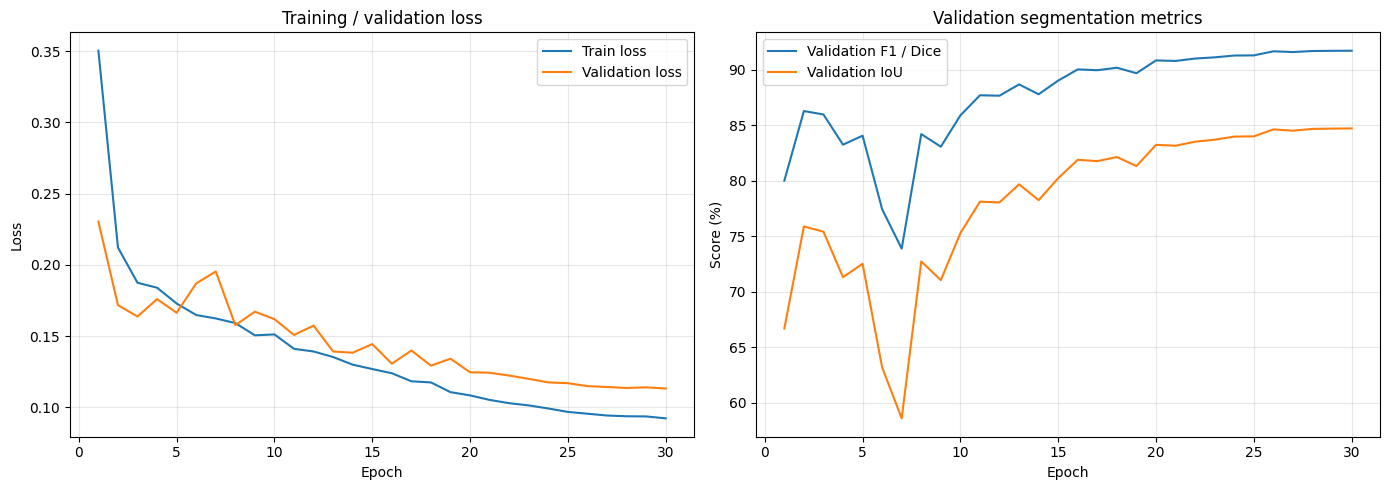

Saved: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run/results/plots/training_curves.png


In [12]:
df = pd.read_csv(CSV_LOG_PATH)
if len(df):
    fig, axes = plt.subplots(1,2,figsize=(14,5))
    axes[0].plot(df.epoch,df.train_loss,label="Train loss")
    axes[0].plot(df.epoch,df.val_loss,label="Validation loss")
    axes[0].set(title="Training / validation loss",xlabel="Epoch",ylabel="Loss")
    axes[0].grid(alpha=.3); axes[0].legend()
    axes[1].plot(df.epoch,df.val_f1*100,label="Validation F1 / Dice")
    axes[1].plot(df.epoch,df.val_iou*100,label="Validation IoU")
    axes[1].set(title="Validation segmentation metrics",xlabel="Epoch",ylabel="Score (%)")
    axes[1].grid(alpha=.3); axes[1].legend()
    plt.tight_layout()
    curve_path=EXP_PLOTS/"training_curves.png"
    plt.savefig(curve_path,dpi=200,bbox_inches="tight"); plt.show()
    print("Saved:",curve_path)
else:
    print("No completed epochs yet.")

## 10. Full validation evaluation and per-image metrics

In [13]:
if not CHECKPOINT_BEST.exists():
    raise FileNotFoundError("Best checkpoint is missing. Run training first.")
eval_model=AttnResUNet34(pretrained=False,num_classes=1).to(device)
best_ckpt=torch.load(CHECKPOINT_BEST,map_location="cpu",weights_only=False)
eval_model.load_state_dict(best_ckpt["model_state_dict"]); eval_model.eval()
global_tracker=GlobalMetricTracker(.5)
per_image_rows=[]
visual_examples=[]

def per_image_scores(pred,truth,eps=1e-8):
    pred=pred.bool(); truth=truth.bool()
    tp=torch.logical_and(pred,truth).sum().item()
    fp=torch.logical_and(pred,~truth).sum().item()
    fn=torch.logical_and(~pred,truth).sum().item()
    tn=torch.logical_and(~pred,~truth).sum().item()
    return {
      "dice":(2*tp+eps)/(2*tp+fp+fn+eps),
      "iou":(tp+eps)/(tp+fp+fn+eps),
      "precision":(tp+eps)/(tp+fp+eps),
      "recall":(tp+eps)/(tp+fn+eps),
      "accuracy":(tp+tn+eps)/(tp+fp+fn+tn+eps),
      "tp":int(tp),"fp":int(fp),"fn":int(fn),"tn":int(tn)
    }

with torch.no_grad():
    for batch_idx,(x,y) in enumerate(tqdm(val_loader,desc="Evaluate best checkpoint")):
        xd,yd=x.to(device,non_blocking=True),y.to(device,non_blocking=True)
        with torch.amp.autocast(device_type="cuda",dtype=torch.float16,enabled=AMP_ENABLED):
            logits=eval_model(xd)
        probs=torch.sigmoid(logits.float()); preds=probs>=.5
        eval_loss=criterion(logits,yd)
        global_tracker.update(logits,yd,eval_loss.item())
        for j in range(x.shape[0]):
            idx=batch_idx*BATCH_SIZE+j
            scores=per_image_scores(preds[j,0].cpu(),y[j,0]>=.5)
            ip,mp=val_pairs[idx]
            per_image_rows.append({"index":idx,"image":ip.name,"mask":mp.name,**scores})
            if len(visual_examples)<12:
                visual_examples.append({"index":idx,"image_name":ip.name,"mask_name":mp.name,
                    "image_tensor":x[j].cpu(),"truth":y[j,0].cpu().numpy(),
                    "probability":probs[j,0].cpu().numpy(),
                    "prediction":preds[j,0].cpu().numpy(),"scores":scores})

global_results=global_tracker.compute()
per_image_df=pd.DataFrame(per_image_rows)
per_image_csv=EXP_EVALUATION/"per_image_validation_metrics.csv"
per_image_df.to_csv(per_image_csv,index=False)
summary={
 "model":"Attn-ResUNet34","checkpoint_epoch":best_ckpt.get("epoch","unknown"),
 "best_epoch":best_ckpt.get("best_epoch","unknown"),"threshold":0.5,
 "validation_images":len(val_pairs),
 "parameters":int(sum(p.numel() for p in eval_model.parameters())),
 "global_pixel_metrics":global_results,
 "per_image_mean_metrics":{k:float(per_image_df[k].mean()) for k in ["dice","iou","precision","recall","accuracy"]},
 "note":"Validation metrics, not an independent held-out test-set estimate."
}
(EXP_EVALUATION/"validation_metrics.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
pct=lambda v:f"{100*v:.2f}%"
report=f'''
Attn-ResUNet34 — Validation Evaluation
Best checkpoint epoch : {summary["best_epoch"]}
Validation images     : {len(val_pairs):,}
Image dimensions      : 512 x 512
Parameters            : {summary["parameters"]:,}
Threshold             : 0.50

GLOBAL PIXEL METRICS
F1 / Dice             : {pct(global_results["f1"])}
IoU / Jaccard          : {pct(global_results["iou"])}
Precision              : {pct(global_results["precision"])}
Recall / Sensitivity   : {pct(global_results["recall"])}
Pixel accuracy         : {pct(global_results["accuracy"])}
Validation loss        : {global_results["loss"]:.6f}

GLOBAL CONFUSION COUNTS
TP: {global_results["tp"]:,} | FP: {global_results["fp"]:,}
FN: {global_results["fn"]:,} | TN: {global_results["tn"]:,}
Total pixels: {global_results["total_pixels"]:,}

MEAN PER-IMAGE METRICS
Mean Dice: {pct(summary["per_image_mean_metrics"]["dice"])}
Mean IoU: {pct(summary["per_image_mean_metrics"]["iou"])}
Mean precision: {pct(summary["per_image_mean_metrics"]["precision"])}
Mean recall: {pct(summary["per_image_mean_metrics"]["recall"])}
Mean pixel accuracy: {pct(summary["per_image_mean_metrics"]["accuracy"])}

Note: validation metrics are not independent test metrics.
'''.strip()
(EXP_EVALUATION/"validation_summary.txt").write_text(report,encoding="utf-8")
print(report)
print("Saved:",per_image_csv)

Evaluate best checkpoint:   0%|          | 0/296 [00:00<?, ?it/s]

Attn-ResUNet34 — Validation Evaluation
Best checkpoint epoch : 30
Validation images     : 2,367
Image dimensions      : 512 x 512
Parameters            : 25,313,269
Threshold             : 0.50

GLOBAL PIXEL METRICS
F1 / Dice             : 91.74%
IoU / Jaccard          : 84.73%
Precision              : 93.13%
Recall / Sensitivity   : 90.39%
Pixel accuracy         : 99.63%
Validation loss        : 0.113281

GLOBAL CONFUSION COUNTS
TP: 12,826,399 | FP: 946,445
FN: 1,364,394 | TN: 605,357,610
Total pixels: 620,494,848

MEAN PER-IMAGE METRICS
Mean Dice: 79.76%
Mean IoU: 73.01%
Mean precision: 87.05%
Mean recall: 81.39%
Mean pixel accuracy: 99.63%

Note: validation metrics are not independent test metrics.
Saved: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run/results/evaluation/per_image_validation_metrics.csv


## 11. Model comparison — historical results clearly labeled

In [14]:
historical=pd.DataFrame([
 {"Model":"ResNet34-FCN","F1 / Dice (%)":93.10,"IoU (%)":87.08,"Precision (%)":94.33,"Recall (%)":91.89,
  "Status":"Historical report; same-pipeline evaluation required"},
 {"Model":"DeepLabV3+ ResNet50","F1 / Dice (%)":93.97,"IoU (%)":88.62,"Precision (%)":95.61,"Recall (%)":92.38,
  "Status":"Historical report; same-pipeline evaluation required"},
])
current=pd.DataFrame([{
 "Model":"Attn-ResUNet34 (this run)","F1 / Dice (%)":100*global_results["f1"],
 "IoU (%)":100*global_results["iou"],"Precision (%)":100*global_results["precision"],
 "Recall (%)":100*global_results["recall"],"Status":"Evaluated by this notebook on validation split"
}])
comparison=pd.concat([historical,current],ignore_index=True)
display(comparison)
comparison.to_csv(EXP_COMPARISON/"model_comparison.csv",index=False)
print("Historical baseline scores are references only. Re-evaluate all models with the same split, preprocessing, threshold, and metric code before claiming a winner.")

,Model,F1 / Dice (%),IoU (%),Precision (%),Recall (%),Status
0,ResNet34-FCN,93.100000,87.080000,94.33000,91.890000,Historical report; same-pipeline evaluation re...
1,DeepLabV3+ ResNet50,93.970000,88.620000,95.61000,92.380000,Historical report; same-pipeline evaluation re...
2,Attn-ResUNet34 (this run),91.736272,84.734078,93.12818,90.385358,Evaluated by this notebook on validation split


Historical baseline scores are references only. Re-evaluate all models with the same split, preprocessing, threshold, and metric code before claiming a winner.


## 12. Validation examples: input image vs expected mask vs model prediction

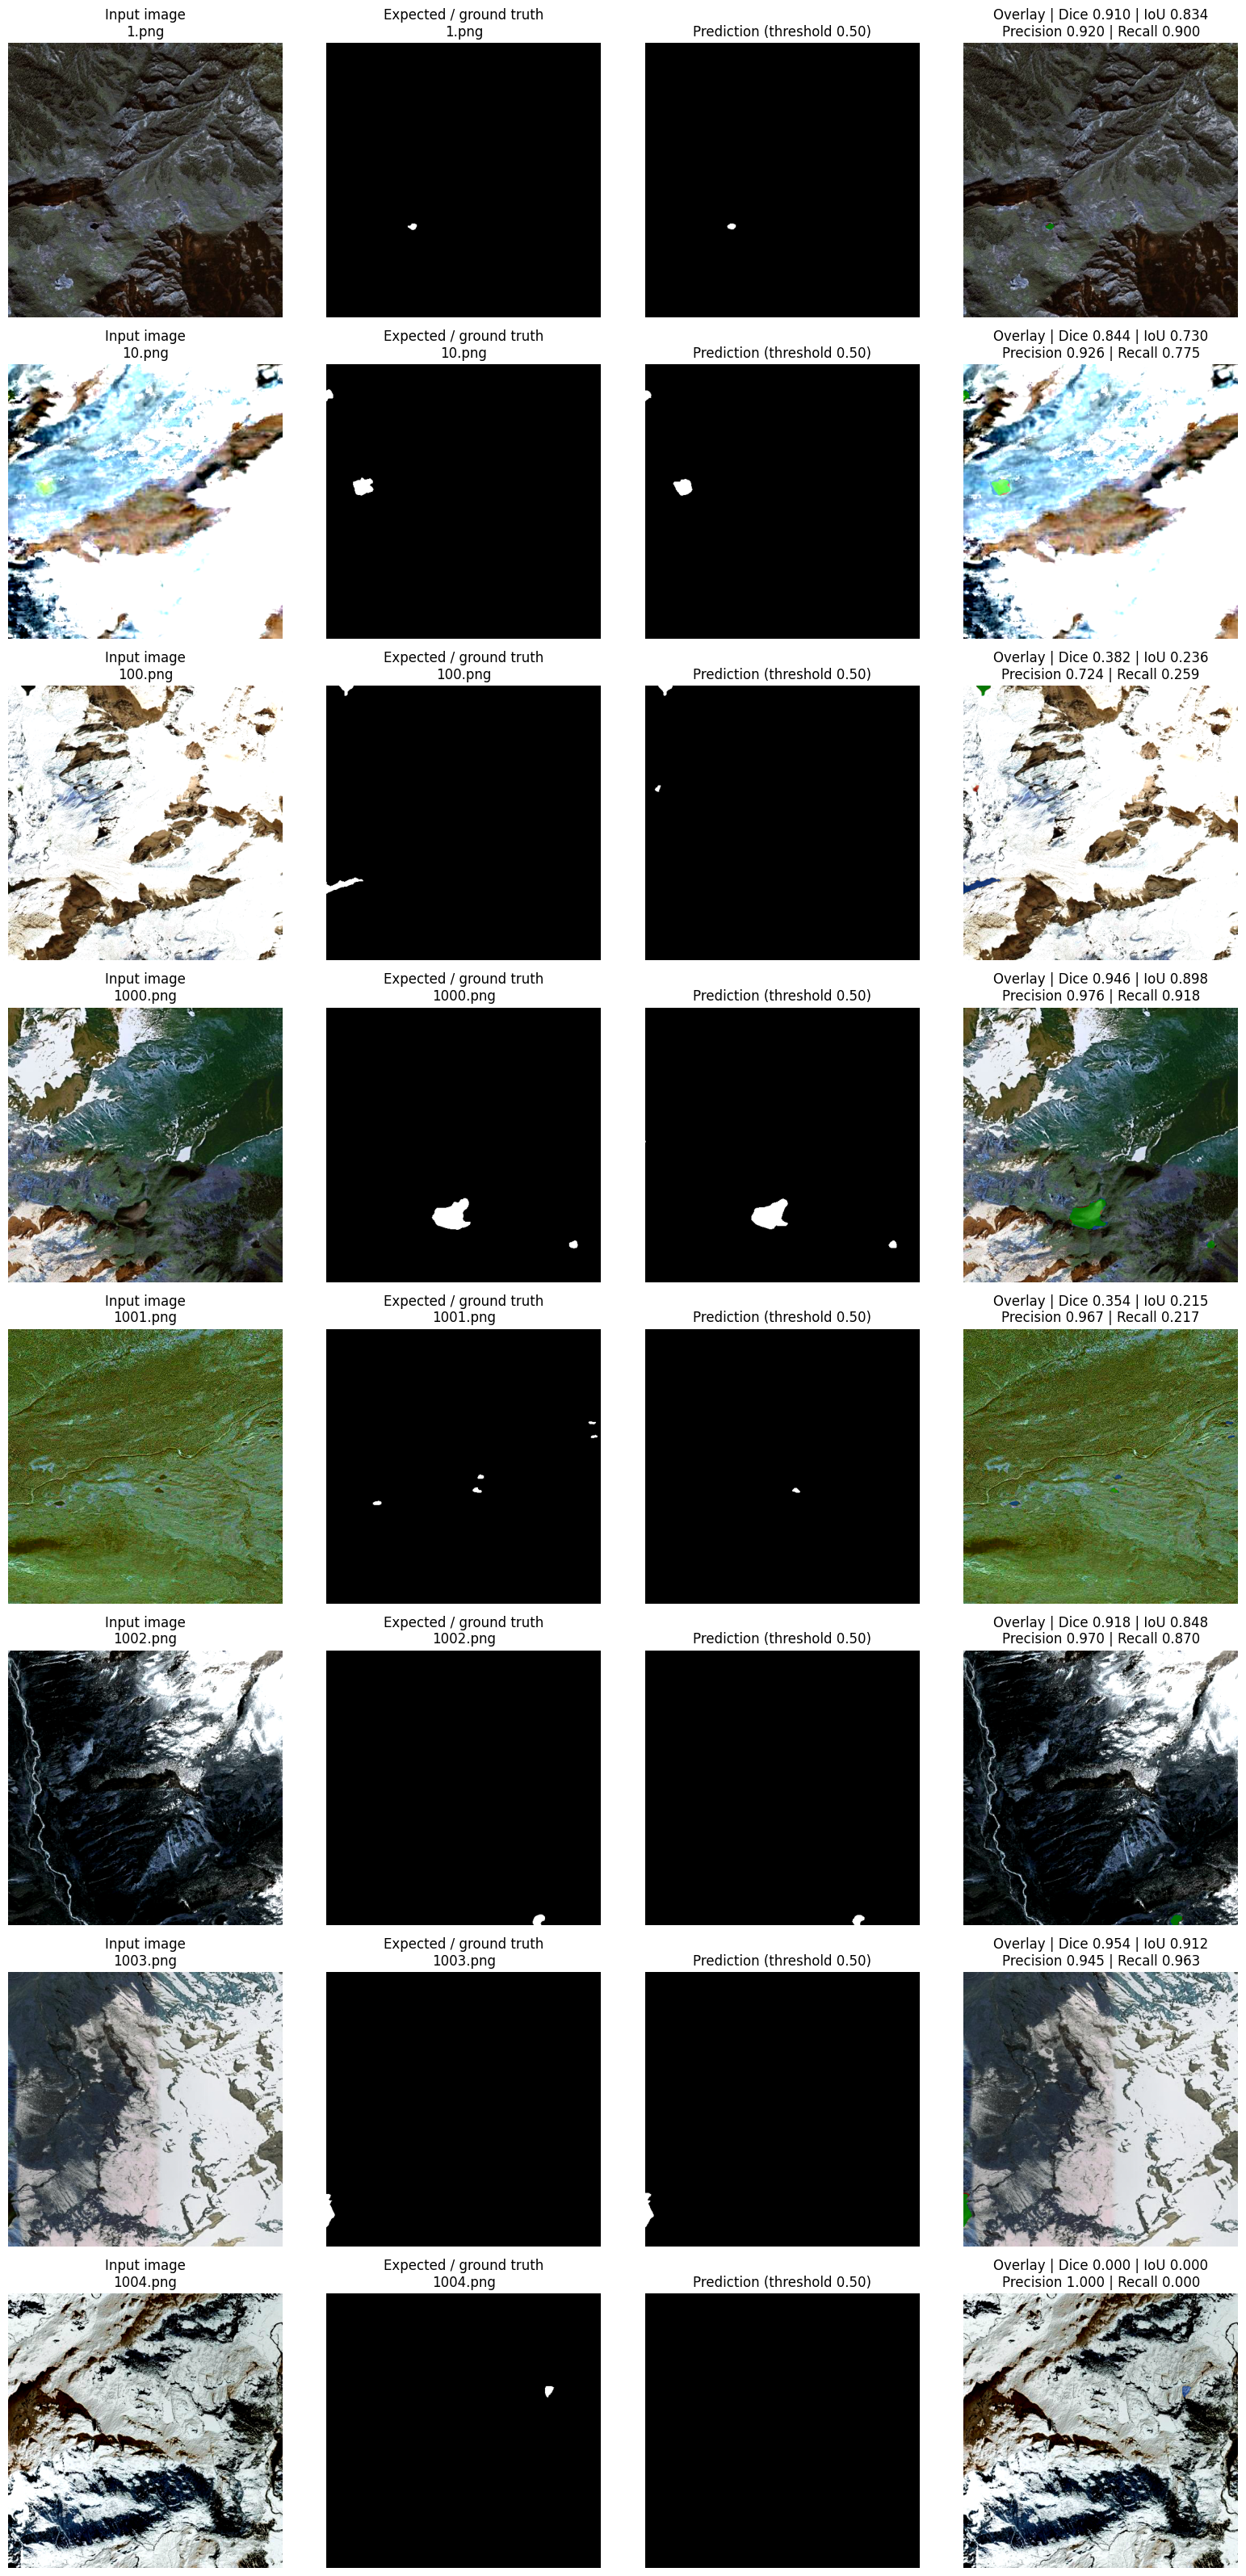

Saved: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run/results/predictions/validation_input_groundtruth_prediction_overlay.png
Overlay colors: green = true positive; red = false positive; blue = false negative.


In [15]:
def denormalize(t):
    mean=torch.tensor(IMAGENET_MEAN).view(3,1,1)
    std=torch.tensor(IMAGENET_STD).view(3,1,1)
    return (t*std+mean).clamp(0,1).permute(1,2,0).numpy()

def overlay_errors(image_np, truth, pred):
    out=image_np.copy()
    tp=(pred==1)&(truth>=.5); fp=(pred==1)&(truth<.5); fn=(pred==0)&(truth>=.5)
    out[tp]=.55*out[tp]+.45*np.array([0.,1.,0.])
    out[fp]=.55*out[fp]+.45*np.array([1.,0.,0.])
    out[fn]=.55*out[fn]+.45*np.array([0.,.35,1.])
    return out

n_show=min(8,len(visual_examples))
fig,axes=plt.subplots(n_show,4,figsize=(16,4*n_show))
if n_show==1: axes=np.expand_dims(axes,0)
for i,s in enumerate(visual_examples[:n_show]):
    img=denormalize(s["image_tensor"]); truth=s["truth"]; pred=s["prediction"].astype(np.uint8); score=s["scores"]
    axes[i,0].imshow(img); axes[i,0].set_title("Input image\n"+s["image_name"])
    axes[i,1].imshow(truth,cmap="gray",vmin=0,vmax=1); axes[i,1].set_title("Expected / ground truth\n"+s["mask_name"])
    axes[i,2].imshow(pred,cmap="gray",vmin=0,vmax=1); axes[i,2].set_title("Prediction (threshold 0.50)")
    axes[i,3].imshow(overlay_errors(img,truth,pred))
    axes[i,3].set_title(f"Overlay | Dice {score['dice']:.3f} | IoU {score['iou']:.3f}\nPrecision {score['precision']:.3f} | Recall {score['recall']:.3f}")
    for ax in axes[i]: ax.axis("off")
plt.tight_layout()
examples_path=EXP_PREDICTIONS/"validation_input_groundtruth_prediction_overlay.png"
plt.savefig(examples_path,dpi=180,bbox_inches="tight"); plt.show()
print("Saved:",examples_path)
print("Overlay colors: green = true positive; red = false positive; blue = false negative.")

## 13. Inspect worst-performing validation images

,index,image,mask,dice,iou,precision,recall,tp,fp,fn
154,154,1137.png,1137.png,2.066799e-13,2.066799e-13,1.000000e+00,2.066799e-13,0,0,48384
766,766,1689.png,1689.png,4.860740e-13,4.860740e-13,1.000000e+00,4.860740e-13,0,0,20573
1190,1190,207.png,207.png,6.567713e-13,6.567713e-13,1.000000e+00,6.567713e-13,0,0,15226
328,328,1294.png,1294.png,1.292157e-12,1.292157e-12,3.333333e-09,1.292658e-12,0,3,7736
1987,1987,657.png,657.png,1.292658e-12,1.292658e-12,1.000000e+00,1.292658e-12,0,0,7736
1453,1453,2306.png,2306.png,1.292658e-12,1.292658e-12,1.000000e+00,1.292658e-12,0,0,7736
623,623,156.png,156.png,1.677852e-12,1.677852e-12,1.000000e+00,1.677852e-12,0,0,5960
942,942,1847.png,1847.png,1.778410e-12,1.778410e-12,1.000000e+00,1.778410e-12,0,0,5623
1510,1510,2358.png,2358.png,2.272727e-12,2.272727e-12,1.000000e-09,2.277904e-12,0,10,4390
494,494,1443.png,1443.png,2.277904e-12,2.277904e-12,1.000000e+00,2.277904e-12,0,0,4390


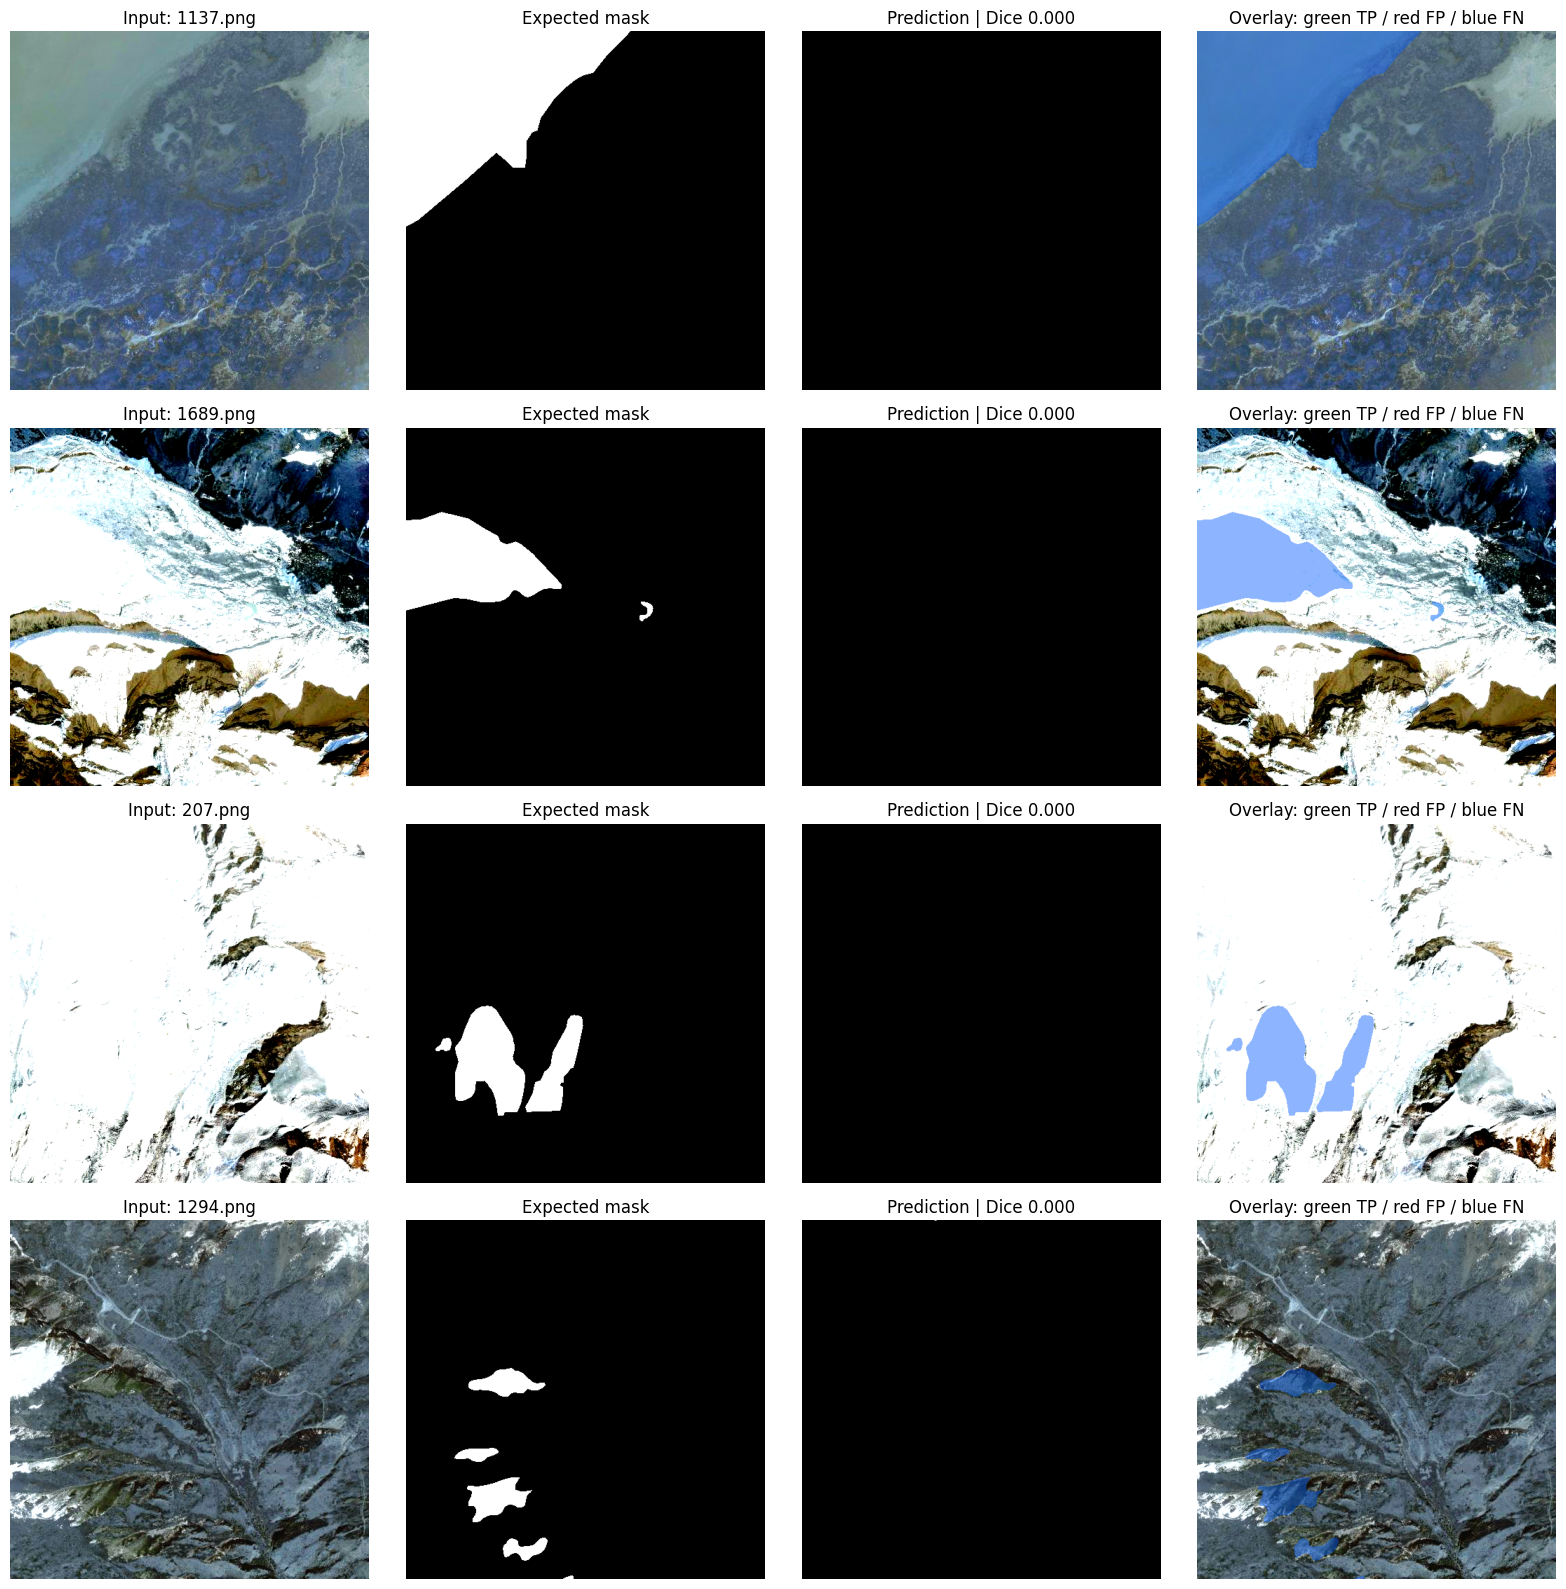

Saved: /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run/results/predictions/worst_validation_cases.png


In [17]:
worst=per_image_df.sort_values("dice",ascending=True).head(12).copy()
display(worst[["index","image","mask","dice","iou","precision","recall","tp","fp","fn"]])
worst.to_csv(EXP_EVALUATION/"lowest_dice_validation_cases.csv",index=False)
worst_indices=worst["index"].astype(int).tolist()[:4]
fig,axes=plt.subplots(len(worst_indices),4,figsize=(16,4*len(worst_indices)))
if len(worst_indices)==1: axes=np.expand_dims(axes,0)
for ri,idx in enumerate(worst_indices):
    ip,mp=val_pairs[idx]
    with Image.open(ip) as im: img=np.asarray(im.convert("RGB").resize((512,512),Image.Resampling.BILINEAR)).astype(np.float32)/255.
    with Image.open(mp) as im: truth=(np.asarray(im.convert("L"))>0).astype(np.uint8)
    x,y=val_dataset[idx]
    with torch.no_grad():
        with torch.amp.autocast(device_type="cuda",dtype=torch.float16,enabled=AMP_ENABLED):
            logits=eval_model(x.unsqueeze(0).to(device))
        pred=(torch.sigmoid(logits.float())[0,0].cpu().numpy()>=.5).astype(np.uint8)
    score=float(worst.loc[worst["index"]==idx,"dice"].iloc[0])
    axes[ri,0].imshow(img); axes[ri,0].set_title("Input: "+ip.name)
    axes[ri,1].imshow(truth,cmap="gray",vmin=0,vmax=1); axes[ri,1].set_title("Expected mask")
    axes[ri,2].imshow(pred,cmap="gray",vmin=0,vmax=1); axes[ri,2].set_title(f"Prediction | Dice {score:.3f}")
    axes[ri,3].imshow(overlay_errors(img,truth,pred)); axes[ri,3].set_title("Overlay: green TP / red FP / blue FN")
    for ax in axes[ri]: ax.axis("off")
plt.tight_layout()
worst_path=EXP_PREDICTIONS/"worst_validation_cases.png"
plt.savefig(worst_path,dpi=180,bbox_inches="tight"); plt.show()
print("Saved:",worst_path)

## 14. Final artifact paths and restart instructions

In [18]:
artifacts={
 "experiment folder":EXP_DIR,"last resumable checkpoint":CHECKPOINT_LAST,
 "best checkpoint":CHECKPOINT_BEST,"training history":CSV_LOG_PATH,"run config":CONFIG_PATH,
 "training curves":EXP_PLOTS/"training_curves.png",
 "validation summary":EXP_EVALUATION/"validation_summary.txt",
 "validation metrics JSON":EXP_EVALUATION/"validation_metrics.json",
 "per-image validation metrics":EXP_EVALUATION/"per_image_validation_metrics.csv",
 "model comparison":EXP_COMPARISON/"model_comparison.csv",
 "validation examples":EXP_PREDICTIONS/"validation_input_groundtruth_prediction_overlay.png",
 "worst cases":EXP_PREDICTIONS/"worst_validation_cases.png",
}
for name,p in artifacts.items():
    print(f"{name:30s}: {p} | exists={Path(p).exists()}")
print("RESTART INSTRUCTIONS")
print("1. If Colab disconnects, reconnect and run the notebook from the top.")
print("2. Dataset files are reused while present locally; after a runtime reset they are restored from the persistent Drive ZIP.")
print("3. Training resumes from this new experiment folder's last_checkpoint.pth. The old experiment is not overwritten.")
print("4. Each completed epoch saves model/optimizer/scheduler/scaler/RNG state and the full history.")
print("5. Historical baseline values are references until re-evaluated with this same pipeline.")
print("6. These are validation metrics, not independent test metrics; use a held-out test split for a scientific test claim.")

experiment folder             : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run | exists=True
last resumable checkpoint     : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run/checkpoints/last_checkpoint.pth | exists=True
best checkpoint               : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run/checkpoints/best_model.pth | exists=True
training history              : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run/results/logs/training_history.csv | exists=True
run config                    : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run/run_config.json | exists=True
training curves               : /content/drive/MyDrive/Glacial_Lake_Segmentation/experiments/attn_resunet34_teacher_final_run/results/plots/training_curves.png | exists=True
validation summar